# QPU Dynamical Decoupling Validation — v4 (relays and optimized results)

One **single job** measures the following in the same batch and with the same physical layout:

| Block | Circuits | Purpose |
|---|---|---|
| Readout calibration | 2 (all-zero, all-one) | Mitigate ⟨X⟩/⟨Y⟩ and establish each qubit's readout floor |
| Main sweep | 3 protocols × ~16 times × X and Y bases | Quadrature coherence \|ρ01\| = √(⟨X⟩²+⟨Y⟩²): removes detuning oscillation |
| Relay references | target idle / target in \|1⟩ at 3 times | **Paired** test of population transfer to each neighbor |
| Spectators in \|1⟩ (ZZ) | free evolution and CPMG at 3 times | Measure how neighbor states affect target phase and whether DD cancels it |

## Changes from v1–v3
1. **Alias-free detuning.** v2/v3 sampled every 26–130 µs; actual detuning (~27 kHz) appeared as 54 kHz, and free T2 was estimated at 62 µs. The new sweep uses a dense segment (≤ 5 µs steps) and X/Y readout.
2. **Physically constrained fits.** Fix C = 0 (coherence decays to zero), weight by shot noise, and inflate errors by √χ² when drift is present. This removes the T2↔C degeneracy that produced error bars larger than the fitted value.
3. **Sound relay measurements.** Count all two-qubit gates (a transpiled SWAP becomes three CZ gates), verify initial and final layouts, and compare each neighbor's population with **its own** idle-target baseline using a two-proportion test and Bonferroni correction.
4. **Delays aligned to dt.** Free evolution, CPMG, and XY4 use exactly the same wait time, without rounding `UserWarning`s. Effective time including pulse duration is reported.
5. **Randomized circuit order** prevents slow drift from correlating with time.
6. **Shots per circuit** (PUBs with their own shot counts) and a **QPU time limit** before submission.
7. **`reuse` mode** reanalyzes a completed job without returning to the queue. **`sim` mode** tests the workflow for free with `FakeFez`.

## Requirements (Kaggle)
Internet enabled · `IBM_QUANTUM_TOKEN` secret · restart the kernel if prompted after `pip`.


## 1. Installation

In [1]:
%pip install -q "qiskit>=1.3" "qiskit-ibm-runtime>=0.30" qiskit-aer matplotlib scipy
print("OK")

Note: you may need to restart the kernel to use updated packages.
OK


## 2. Embedded `ddqpu` package
This cell writes the repository package to `./ddqpu/`. If you cloned the repository, you can skip this cell and run `pip install -e .`.

In [2]:
import pathlib, importlib, sys
_FILES = {}
_FILES['__init__.py'] = '"""Validate dynamical decoupling on IBM QPUs with relay control.\n\nImport modules explicitly (for example, ``ddqpu.circuits`` or\n``ddqpu.sentinel``) so helper tools do not load the full Qiskit stack\nwhen they only need independent utilities.\n"""\n__version__ = "5.0.0"\n'
_FILES['circuits.py'] = '"""Build DD circuits with spectators (neighbors + control) and delays aligned to dt.\n\nBit convention: bit 0 = target, bits 1..k = neighbors, final bit = distant control.\nMeasure all layout qubits in every circuit so each circuit also provides relay data\n(spectator populations) without requiring extra circuits.\n"""\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, asdict, field\nfrom typing import List, Sequence\n\nimport numpy as np\nfrom qiskit import QuantumCircuit\n\nPROTOCOLS = ("free", "cpmg", "xy4")\nBASES = ("X", "Y")\n\n\n@dataclass\nclass Timing:\n    """Backend timing constraints (all values are in dt units)."""\n    dt: float                 # segundos por muestra\n    granularity: int = 16     # required multiple for delay duration\n    min_length: int = 64\n    x_duration_dt: int = 0    # duration of an X/Y pulse (for effective time)\n\n    def us_to_dt(self, t_us: float) -> int:\n        """Round t_us to the nearest granularity multiple (avoids rounding UserWarnings\n        and ensures free/CPMG/XY4 use exactly the same wait time)."""\n        n = int(round(t_us * 1e-6 / self.dt))\n        g = max(int(self.granularity), 1)\n        return int(round(n / g) * g)\n\n    def dt_to_us(self, n: int) -> float:\n        return n * self.dt * 1e6\n\n\ndef timing_from_backend(backend) -> Timing:\n    target = backend.target\n    dt = float(target.dt or backend.dt)\n    gran, minlen = 16, 64\n    try:\n        tc = target.timing_constraints()\n        gran, minlen = int(tc.granularity), int(tc.min_length)\n    except Exception:\n        pass\n    xdur = 0\n    try:\n        q0 = next(iter(target["x"].keys()))\n        d = target["x"][q0].duration\n        if d:\n            xdur = int(round(d / dt))\n    except Exception:\n        pass\n    return Timing(dt=dt, granularity=max(gran, 1), min_length=max(minlen, 1), x_duration_dt=xdur)\n\n\n@dataclass\nclass CircuitSpec:\n    """Metadata for one batch circuit (serialized in the job manifest)."""\n    kind: str                 # main | cal0 | cal1 | idle | exc1 | zz | nsweep\n    protocol: str = "none"    # free | cpmg | xy4 | none\n    basis: str = "Z"          # X | Y | Z\n    t_us: float = 0.0         # nominal wait time aligned to dt\n    t_eff_us: float = 0.0     # total time including DD pulses\n    n_pulses: int = 0\n    spectator_state: str = "0"  # prepared state of neighboring spectators\n    shots: int = 0\n    extra: dict = field(default_factory=dict)\n\n    def to_dict(self):\n        return asdict(self)\n\n\ndef _pulse_sequence(protocol: str, n_cpmg: int, n_xy4_cycles: int) -> List[str]:\n    if protocol == "cpmg":\n        return ["x"] * n_cpmg\n    if protocol == "xy4":\n        return ["x", "y", "x", "y"] * max(n_xy4_cycles, 1)\n    return []\n\n\ndef _dd_block(qc: QuantumCircuit, q: int, total_dt: int, pulses: Sequence[str], timing: Timing):\n    """Build tau/2 - P - tau - P - ... - P - tau/2 with delays in dt and granularity multiples.\n    Absorb rounding residual in the final segment to preserve the exact total duration."""\n    if total_dt <= 0:\n        return\n    if not pulses:\n        qc.delay(total_dt, q, unit="dt")\n        return\n    n = len(pulses)\n    g = timing.granularity\n    half = int((total_dt / (2 * n)) // g * g)\n    full = 2 * half\n    used = half + full * (n - 1) + half\n    last = half + (total_dt - used)\n    if half > 0:\n        qc.delay(half, q, unit="dt")\n    for i, p in enumerate(pulses):\n        getattr(qc, p)(q)\n        seg = full if i < n - 1 else last\n        if seg > 0:\n            qc.delay(seg, q, unit="dt")\n\n\ndef build_coherence_circuit(\n    protocol: str,\n    t_us: float,\n    basis: str,\n    n_spectators: int,\n    timing: Timing,\n    n_cpmg: int = 6,\n    n_xy4_cycles: int = 2,\n    spectator_state: str = "0",\n    n_neighbors: int = 2,\n):\n    """Prepare target in |+>, wait with/without DD, and measure in X or Y. Spectators are idle."""\n    n = 1 + n_spectators\n    t_dt = timing.us_to_dt(t_us)\n    pulses = _pulse_sequence(protocol, n_cpmg, n_xy4_cycles) if t_dt > 0 else []\n    qc = QuantumCircuit(n, n, name=f"{protocol}_{basis}_{t_dt}dt_s{spectator_state}")\n    if spectator_state == "1":\n        for k in range(1, 1 + n_neighbors):\n            qc.x(k)\n    qc.h(0)\n    qc.barrier()\n    _dd_block(qc, 0, t_dt, pulses, timing)\n    qc.barrier()\n    if basis == "Y":\n        qc.sdg(0)\n    qc.h(0)\n    qc.measure(range(n), range(n))\n    t_eff = timing.dt_to_us(t_dt + len(pulses) * timing.x_duration_dt)\n    spec = CircuitSpec(kind="main" if spectator_state == "0" else "zz", protocol=protocol, basis=basis,\n                       t_us=timing.dt_to_us(t_dt), t_eff_us=t_eff, n_pulses=len(pulses),\n                       spectator_state=spectator_state)\n    return qc, spec\n\n\ndef build_readout_cal(n_qubits: int, state: str):\n    qc = QuantumCircuit(n_qubits, n_qubits, name=f"cal{state}")\n    if state == "1":\n        qc.x(range(n_qubits))\n    qc.barrier()\n    qc.measure(range(n_qubits), range(n_qubits))\n    return qc, CircuitSpec(kind=f"cal{state}")\n\n\ndef build_relay_reference(t_us: float, n_spectators: int, timing: Timing, target_state: str):\n    """Paired relay reference.\n    target_state=\'0\' -> idle target (each neighbor\'s baseline at the same t).\n    target_state=\'1\' -> target excited in |1> (more sensitive to exchange-mediated transfer)."""\n    n = 1 + n_spectators\n    t_dt = timing.us_to_dt(t_us)\n    qc = QuantumCircuit(n, n, name=f"relay_t{target_state}_{t_dt}dt")\n    if target_state == "1":\n        qc.x(0)\n    qc.barrier()\n    if t_dt > 0:\n        qc.delay(t_dt, 0, unit="dt")\n    qc.barrier()\n    qc.measure(range(n), range(n))\n    kind = "idle" if target_state == "0" else "exc1"\n    return qc, CircuitSpec(kind=kind, t_us=timing.dt_to_us(t_dt), t_eff_us=timing.dt_to_us(t_dt))\n\n\ndef default_time_grid(t2_ref_us: float, fractions: Sequence[float] | None = None, t_max_us: float = 450.0,\n                      dense_us: Sequence[float] | None = None):\n    """Two-segment time grid:\n    - dense absolute segment (step <= 5 us up to 40 us): resolves phase without aliasing for |detuning| < ~100 kHz\n      (in v2/v3, 26–130 µs steps aliased the actual ~27 kHz detuning to ~54 kHz);\n    - segment scaled to calibrated T2 (0.2x–1.6x): resolves the envelope and beta."""\n    if dense_us is None:\n        dense_us = [2, 5, 10, 15, 20, 25, 30, 40]\n    if fractions is None:\n        fractions = [0.2, 0.3, 0.45, 0.6, 0.8, 1.0, 1.3, 1.6]\n    grid = set(float(t) for t in dense_us)\n    grid |= set(round(min(f * t2_ref_us, t_max_us), 1) for f in fractions)\n    grid = sorted(g for g in grid if g > 0)\n    # Remove near-duplicate points (<3 us).\n    out = []\n    for g in grid:\n        if not out or g - out[-1] >= 3.0:\n            out.append(g)\n    return out\n\n\ndef expected_parity_z(qc: QuantumCircuit) -> int:\n    """Testing utility: number of X/Y gates on target (must be even to return to |+>)."""\n    return sum(1 for ins in qc.data if ins.operation.name in ("x", "y") and qc.find_bit(ins.qubits[0]).index == 0)\n\n\n__all__ = [\n    "PROTOCOLS", "BASES", "Timing", "timing_from_backend", "CircuitSpec",\n    "build_coherence_circuit", "build_readout_cal", "build_relay_reference", "default_time_grid",\n]\n_ = np  # numpy reservado para extensiones\n'
_FILES['backend_utils.py'] = '"""Qubit selection, spectator layout, verified transpilation, and QPU runtime estimation."""\nfrom __future__ import annotations\n\nimport os\nfrom dataclasses import dataclass, asdict\nfrom typing import Dict, List, Optional\n\nimport numpy as np\n\nTWO_Q_GATES = {"cz", "ecr", "cx", "swap", "rzz", "iswap", "cy", "cp", "rzx"}\n\n\ndef get_token() -> str:\n    try:\n        from kaggle_secrets import UserSecretsClient  # type: ignore\n        t = UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN")\n        if t:\n            return t.strip()\n    except Exception:\n        pass\n    t = os.environ.get("QISKIT_IBM_TOKEN") or os.environ.get("IBM_QUANTUM_TOKEN")\n    if not t:\n        raise RuntimeError("Configure the IBM_QUANTUM_TOKEN secret (Kaggle) or the QISKIT_IBM_TOKEN variable")\n    return t.strip()\n\n\ndef get_service(channel: str = "ibm_cloud", instance: Optional[str] = "open-instance"):\n    """Create the service without writing the token to disk (save_account is not needed per run)."""\n    from qiskit_ibm_runtime import QiskitRuntimeService\n    kw = {"channel": channel, "token": get_token()}\n    if instance:\n        kw["instance"] = instance\n    return QiskitRuntimeService(**kw)\n\n\n@dataclass\nclass QubitInfo:\n    q: int\n    t1_us: float\n    t2_us: float\n    sx_err: float\n    ro_err: float\n    score: float\n\n\ndef _qubit_info(backend, q: int) -> Optional[QubitInfo]:\n    tgt = backend.target\n    try:\n        qp = tgt.qubit_properties[q]\n        t1 = (qp.t1 or 0.0) * 1e6\n        t2 = (qp.t2 or 0.0) * 1e6\n    except Exception:\n        return None\n    if t2 <= 0 or t1 <= 0:\n        return None\n\n    def err(op):\n        try:\n            e = tgt[op][(q,)].error\n            return float(e) if e is not None else None\n        except Exception:\n            return None\n\n    sx = err("sx") or err("x") or 1e-2\n    ro = err("measure") or 5e-2\n    # T2 > 2*T1 is unphysical: calibration may be suspect, so the value is capped\n    t2_eff = min(t2, 2.0 * t1)\n    score = t2_eff / (1.0 + 50.0 * sx + 10.0 * ro)\n    return QubitInfo(q, t1, t2, sx, ro, score)\n\n\ndef rank_qubits(backend, top: int = 8) -> List[QubitInfo]:\n    rows = [r for q in range(backend.num_qubits) if (r := _qubit_info(backend, q))]\n    rows.sort(key=lambda r: -r.score)\n    return rows[:top] if top else rows\n\n\ndef bfs_distances(backend, source: int) -> Dict[int, int]:\n    adj: Dict[int, set] = {q: set() for q in range(backend.num_qubits)}\n    for a, b in backend.coupling_map.get_edges():\n        adj[a].add(b)\n        adj[b].add(a)\n    dist = {source: 0}\n    frontier = [source]\n    while frontier:\n        nxt = []\n        for u in frontier:\n            for v in adj[u]:\n                if v not in dist:\n                    dist[v] = dist[u] + 1\n                    nxt.append(v)\n        frontier = nxt\n    return dist\n\n\n@dataclass\nclass Layout:\n    target: int\n    target_t2_us: float\n    target_t1_us: float\n    neighbors: List[int]\n    control: int\n    control_distance: int\n\n    @property\n    def physical(self) -> List[int]:\n        return [self.target] + list(self.neighbors) + [self.control]\n\n    def to_dict(self):\n        d = asdict(self)\n        d["physical"] = self.physical\n        return d\n\n\ndef choose_layout(backend, force_target: Optional[int] = None, n_neighbors: int = 2,\n                  min_control_distance: int = 4) -> Layout:\n    ranked = rank_qubits(backend, top=0)\n    info = {r.q: r for r in ranked}\n    if force_target is not None:\n        tq = int(force_target)\n    else:\n        tq = ranked[0].q\n    ti = info.get(tq) or _qubit_info(backend, tq)\n    dist = bfs_distances(backend, tq)\n    nbs = sorted([q for q, d in dist.items() if d == 1], key=lambda q: -(info[q].score if q in info else 0))\n    if not nbs:\n            raise RuntimeError(f"q{tq} has no neighbors in the coupling map")\n    # Measure ALL available direct neighbors, up to n_neighbors (typically 2–3 on heavy-hex).\n    nbs = nbs[:n_neighbors]\n    # Distant control: good readout (reliable baseline), far from target and neighbors.\n    far = [q for q, d in dist.items() if d >= min_control_distance and q in info]\n    if not far:\n        far = [q for q, d in dist.items() if d >= 2 and q in info]\n    far.sort(key=lambda q: (info[q].ro_err, -info[q].t1_us))\n    cq = far[0]\n    return Layout(tq, ti.t2_us, ti.t1_us, nbs, cq, dist[cq])\n\n\ndef transpile_locked(circuits, backend, layout: Layout, optimization_level: int = 1):\n    """Transpile with a fixed layout and NO routing. Return (transpiled circuits, relay report)."""\n    from qiskit.transpiler import generate_preset_pass_manager\n    pm = generate_preset_pass_manager(optimization_level=optimization_level, backend=backend,\n                                      initial_layout=layout.physical)\n    tcs = pm.run(list(circuits))\n    report = verify_no_relay(tcs, layout)\n    return tcs, report\n\n\ndef verify_no_relay(transpiled, layout: Layout) -> dict:\n    """Structural relay verification.\n    - Count two-qubit gates (a transpiled SWAP appears as three CZ/ECR gates, not as \'swap\').\n    - Verify the initial and final layout of every logical qubit.\n    - Verify that measurement of bit 0 occurs on the physical target qubit."""\n    issues = []\n    for i, tc in enumerate(transpiled):\n        ops = tc.count_ops()\n        n2q = sum(v for k, v in ops.items() if k in TWO_Q_GATES)\n        if n2q:\n            issues.append(f"circuit {i} ({tc.name}): {n2q} two-qubit gates")\n        lay = tc.layout\n        if lay is not None:\n            try:\n                init = lay.initial_index_layout(filter_ancillas=True)\n                fin = lay.final_index_layout(filter_ancillas=True)\n                if list(init) != layout.physical:\n                    issues.append(f"circuit {i}: initial layout {list(init)} != {layout.physical}")\n                if list(fin) != layout.physical:\n                    issues.append(f"circuit {i}: final layout {list(fin)} != {layout.physical}")\n            except Exception as e:  # pragma: no cover\n                issues.append(f"circuit {i}: could not read layout ({e})")\n        for ins in tc.data:\n            if ins.operation.name == "measure":\n                pq = tc.find_bit(ins.qubits[0]).index\n                cb = tc.find_bit(ins.clbits[0]).index\n                if cb == 0 and pq != layout.target:\n                    issues.append(f"circuit {i}: bit 0 measured on q{pq} (expected q{layout.target})")\n    return {"ok": not issues, "issues": issues, "n_circuits": len(transpiled)}\n\n\ndef estimate_qpu_seconds(specs, backend, rep_delay_s: Optional[float] = None) -> float:\n    """Approximate runtime: sum(shots * (effective time + measurement + rep_delay)) + ~2 s overhead."""\n    if rep_delay_s is None:\n        rep_delay_s = getattr(backend, "default_rep_delay", None) or 250e-6\n    try:\n        meas = backend.target["measure"][(0,)].duration or 1.6e-6\n    except Exception:\n        meas = 1.6e-6\n    total = sum(s.shots * (s.t_eff_us * 1e-6 + meas + rep_delay_s) for s in specs)\n    return float(total + 2.0)\n\n\n_ = np\n'
_FILES['analysis.py'] = '"""Offline analysis: readout mitigation, quadrature coherence, weighted fits,\nrelay statistics (paired tests), and spectator-induced ZZ shifts."""\nfrom __future__ import annotations\n\nimport math\nfrom typing import Dict, List, Optional, Sequence\n\nimport numpy as np\nfrom scipy.optimize import curve_fit\nfrom scipy.stats import norm\n\n\n# ---------------------------------------------------------------- counts\ndef counts_from_pub(pub) -> dict:\n    data = pub.data\n    for key in ("c", "meas"):\n        if hasattr(data, key):\n            return getattr(data, key).get_counts()\n    for key in data:\n        try:\n            return data[key].get_counts()\n        except Exception:\n            continue\n    return {}\n\n\ndef bit_counts(counts: dict, bit: int):\n    """Return (n0, n1) for classical bit `bit` (0 is the rightmost bit)."""\n    n0 = n1 = 0\n    for k, v in counts.items():\n        b = str(k).replace(" ", "")[-1 - bit]\n        if b == "0":\n            n0 += int(v)\n        else:\n            n1 += int(v)\n    return n0, n1\n\n\n# ---------------------------------------------------------------- readout\ndef readout_errors(cal0: dict, cal1: dict, n_bits: int):\n    """Return per-qubit e0[b] = P(1|0), e1[b] = P(0|1) from same-job calibration circuits."""\n    e0, e1 = [], []\n    for b in range(n_bits):\n        a0, a1 = bit_counts(cal0, b)\n        c0, c1 = bit_counts(cal1, b)\n        e0.append(a1 / max(a0 + a1, 1))\n        e1.append(c0 / max(c0 + c1, 1))\n    return np.array(e0), np.array(e1)\n\n\ndef mitigated_expectation(counts: dict, bit: int, e0: float, e1: float):\n    """Return <Z> corrected by the single-qubit assignment matrix and its standard error."""\n    n0, n1 = bit_counts(counts, bit)\n    n = max(n0 + n1, 1)\n    pm1 = n1 / n\n    denom = max(1.0 - e0 - e1, 0.5)\n    p1 = float(np.clip((pm1 - e0) / denom, 0.0, 1.0))\n    ez = 1.0 - 2.0 * p1\n    se = 2.0 * math.sqrt(max(pm1 * (1 - pm1), 1.0 / n) / n) / denom\n    return ez, se\n\n\n# ---------------------------------------------------------------- coherence\ndef coherence_from_xy(x, y, sx, sy):\n    """Return |rho01| = sqrt(<X>^2 + <Y>^2), shot-noise bias correction, and phase."""\n    x, y, sx, sy = map(lambda a: np.asarray(a, float), (x, y, sx, sy))\n    mag2 = x ** 2 + y ** 2 - (sx ** 2 + sy ** 2)\n    mag = np.sqrt(np.clip(mag2, 0.0, None))\n    se = np.sqrt((x * sx) ** 2 + (y * sy) ** 2) / np.maximum(mag, 1e-3)\n    se = np.maximum(se, np.sqrt(0.5 * (sx ** 2 + sy ** 2)))\n    phase = np.arctan2(y, x)\n    return mag, se, phase\n\n\ndef stretched(t, A, T2, beta):\n    return A * np.exp(-((np.maximum(t, 0.0) / T2) ** beta))\n\n\ndef fit_envelope(t, y, se, beta_fixed: Optional[float] = None, label: str = "") -> Optional[dict]:\n    """Fit weighted A*exp(-(t/T2)^beta) with C = 0 (coherence physically decays to zero).\n    Fixing C removes the T2<->C degeneracy that produced error bars larger than estimates in v1-v3.\n    Inflate the error by sqrt(chi2_red) when temporal drift is present (chi2_red > 1)."""\n    t, y, se = map(lambda a: np.asarray(a, float), (t, y, se))\n    ok = np.isfinite(y) & np.isfinite(se)\n    t, y, se = t[ok], y[ok], np.maximum(se[ok], 1e-3)\n    if len(t) < 3 or np.nanmax(y) < 0.05:\n        return None\n    # Initial T0: first 1/e crossing\n    below = np.where(y < y[0] / math.e)[0]\n    T0 = float(t[below[0]]) if len(below) else float(t[-1] * 2)\n    try:\n        if beta_fixed is None:\n            f = stretched\n            p0, lo, hi = [min(y[0], 1.0), T0, 1.0], [0.0, 0.5, 0.5], [1.2, 20 * t[-1], 3.0]\n        else:\n            f = lambda tt, A, T2: stretched(tt, A, T2, beta_fixed)  # noqa: E731\n            p0, lo, hi = [min(y[0], 1.0), T0], [0.0, 0.5], [1.2, 20 * t[-1]]\n        popt, pcov = curve_fit(f, t, y, p0=p0, sigma=se, absolute_sigma=True, bounds=(lo, hi), maxfev=20000)\n    except Exception as e:\n        print(f"Fit {label} failed: {e}")\n        return None\n    perr = np.sqrt(np.diag(pcov))\n    dof = max(len(t) - len(popt), 1)\n    chi2 = float(np.sum(((f(t, *popt) - y) / se) ** 2) / dof)\n    infl = math.sqrt(max(chi2, 1.0))\n    out = {"A": float(popt[0]), "T2": float(popt[1]), "T2_err": float(perr[1] * infl),\n           "beta": float(popt[2]) if beta_fixed is None else float(beta_fixed),\n           "beta_err": float(perr[2] * infl) if beta_fixed is None else 0.0,\n           "chi2_red": chi2, "n_points": int(len(t))}\n    out["reliable"] = bool(out["T2_err"] < 0.3 * out["T2"] and t[-1] > 0.7 * out["T2"])\n    return out\n\n\ndef detuning_from_phase(t, phase, mag, min_mag: float = 0.25, max_gap_us: float = 10.0):\n    """Estimate detuning frequency (kHz) by unwrapping phase in the dense portion of the grid.\n    Use only consecutive points separated by <= max_gap_us (alias-free when |f| < 1/(2*gap))."""\n    t, phase, mag = map(lambda a: np.asarray(a, float), (t, phase, mag))\n    sel = [0] if len(t) else []\n    for i in range(1, len(t)):\n        if mag[i] < min_mag or (t[i] - t[sel[-1]]) > max_gap_us:\n            break\n        sel.append(i)\n    if len(sel) < 3:\n        return None\n    ts, ph = t[sel], np.unwrap(phase[sel])\n    A = np.vstack([ts, np.ones_like(ts)]).T\n    coef, res, *_ = np.linalg.lstsq(A, ph, rcond=None)\n    slope = coef[0]\n    resid = ph - A @ coef\n    s2 = float(np.sum(resid ** 2) / max(len(ts) - 2, 1))\n    cov = s2 * np.linalg.inv(A.T @ A)\n    f_khz = slope / (2 * math.pi) * 1e3\n    f_err = math.sqrt(max(cov[0, 0], 0)) / (2 * math.pi) * 1e3\n    return {"f_kHz": float(f_khz), "f_err_kHz": float(f_err), "n_points": len(sel),\n            "t_max_us": float(ts[-1])}\n\n\ndef ratio_with_err(a, ea, b, eb):\n    r = a / b\n    return r, abs(r) * math.sqrt((ea / a) ** 2 + (eb / b) ** 2)\n\n\n# ---------------------------------------------------------------- relays\ndef two_proportion_test(k1, n1, k0, n0):\n    """Compute the proportion difference (p1 - p0), error, z, and one-sided p-value (p1 > p0)\n    and the one-sided 95% upper bound."""\n    p1, p0 = k1 / max(n1, 1), k0 / max(n0, 1)\n    p = (k1 + k0) / max(n1 + n0, 1)\n    se_pool = math.sqrt(max(p * (1 - p), 1e-12) * (1 / max(n1, 1) + 1 / max(n0, 1)))\n    se = math.sqrt(max(p1 * (1 - p1), 1 / max(n1, 1) ** 2) / max(n1, 1)\n                   + max(p0 * (1 - p0), 1 / max(n0, 1) ** 2) / max(n0, 1))\n    z = (p1 - p0) / se_pool if se_pool > 0 else 0.0\n    return {"delta": p1 - p0, "se": se, "z": z, "p_value": float(1 - norm.cdf(z)),\n            "upper95": (p1 - p0) + 1.645 * se, "p_active": p1, "p_ref": p0}\n\n\ndef relay_statistics(records: List[dict], neighbor_bits: Sequence[int], control_bit: int) -> dict:\n    """Records are dictionaries with \'spec\' (CircuitSpec dictionary) and \'counts\'.\n    Compare each spectator\'s P(1) with the target active (main, in |+>) or excited (exc1)\n    against the idle-target reference, aggregating across circuits."""\n    def pool(kinds, bit):\n        k = n = 0\n        for r in records:\n            if r["spec"]["kind"] in kinds:\n                n0, n1 = bit_counts(r["counts"], bit)\n                k += n1\n                n += n0 + n1\n        return k, n\n\n    out = {}\n    for label, bit in [*[(f"vecino_bit{b}", b) for b in neighbor_bits], ("control", control_bit)]:\n        k_ref, n_ref = pool(("idle",), bit)\n        k_act, n_act = pool(("main",), bit)\n        k_exc, n_exc = pool(("exc1",), bit)\n        out[label] = {\n            "activo_vs_idle": two_proportion_test(k_act, n_act, k_ref, n_ref),\n            "excitado_vs_idle": two_proportion_test(k_exc, n_exc, k_ref, n_ref),\n            "n_ref": n_ref, "n_act": n_act, "n_exc": n_exc,\n        }\n    return out\n\n\ndef relay_verdict(stats: dict, alpha: float = 0.01, max_transfer: float = 0.005) -> dict:\n    """A relay is detected if any neighbor shows a significant excess in P(1) (p < alpha, with\n    Bonferroni correction) and a relevant magnitude (> max_transfer). Otherwise, report the upper bound."""\n    tests = [(lab, key, s[key]) for lab, s in stats.items() if lab.startswith("vecino")\n             for key in ("activo_vs_idle", "excitado_vs_idle")]\n    m = max(len(tests), 1)\n    flagged = [(lab, key, t) for lab, key, t in tests\n               if t["p_value"] < alpha / m and t["delta"] > max_transfer]\n    worst_upper = max((t["upper95"] for _, _, t in tests), default=float("nan"))\n    return {"relay_detected": bool(flagged), "flagged": [(a, b) for a, b, _ in flagged],\n            "worst_upper95": worst_upper, "bonferroni_m": m}\n\n\n__all__ = [n for n in dir() if not n.startswith("_")]\n'
_FILES['experiment.py'] = '"""Orchestrate one job with a main sweep, relay references, ZZ measurements, and readout calibration."""\nfrom __future__ import annotations\n\nimport json\nimport random\nimport time\nfrom dataclasses import dataclass, field, asdict\nfrom pathlib import Path\nfrom typing import List, Optional\n\nimport numpy as np\n\nfrom .circuits import (PROTOCOLS, BASES, build_coherence_circuit, build_readout_cal,\n                       build_relay_reference, default_time_grid, timing_from_backend)\nfrom .backend_utils import choose_layout, transpile_locked, estimate_qpu_seconds, Layout\nfrom . import analysis as A\n\n\n@dataclass\nclass Config:\n    backend_name: str = "ibm_fez"\n    force_target: Optional[int] = None       # e.g., 142 to compare with previous runs\n    n_neighbors: int = 2\n    n_cpmg: int = 6\n    n_xy4_cycles: int = 2\n    shots_main: int = 1024                   # per basis; X+Y => 2048 effective shots per point\n    shots_ref: int = 2048                    # referencias de relevo (se agregan entre tiempos)\n    shots_cal: int = 4096\n    t2_fractions: Optional[List[float]] = None\n    t_max_us: float = 450.0\n    relay_fractions: List[float] = field(default_factory=lambda: [0.1, 0.5, 1.0])\n    zz_fractions: List[float] = field(default_factory=lambda: [0.05, 0.10, 0.20])\n    enable_zz: bool = True\n    shuffle_seed: Optional[int] = 1234       # randomized order prevents drift from correlating with t\n    optimization_level: int = 1\n    max_qpu_seconds: float = 240.0           # safety limit for the Open plan (10 min/month)\n\n\ndef build_batch(cfg: Config, backend, layout: Optional[Layout] = None):\n    layout = layout or choose_layout(backend, cfg.force_target, cfg.n_neighbors)\n    timing = timing_from_backend(backend)\n    n_spec = len(layout.physical) - 1\n    grid = default_time_grid(layout.target_t2_us, cfg.t2_fractions, cfg.t_max_us)\n    circs, specs = [], []\n\n    def add(qc, spec, shots):\n        spec.shots = shots\n        circs.append(qc)\n        specs.append(spec)\n\n    n = len(layout.physical)\n    for st in ("0", "1"):\n        add(*build_readout_cal(n, st), cfg.shots_cal)\n    for prot in PROTOCOLS:\n        for t in grid:\n            for b in BASES:\n                add(*build_coherence_circuit(prot, t, b, n_spec, timing, cfg.n_cpmg, cfg.n_xy4_cycles,\n                                             "0", cfg.n_neighbors), cfg.shots_main)\n    for f in cfg.relay_fractions:\n        t = f * layout.target_t2_us\n        add(*build_relay_reference(t, n_spec, timing, "0"), cfg.shots_ref)\n        add(*build_relay_reference(t, n_spec, timing, "1"), cfg.shots_ref)\n    if cfg.enable_zz:\n        # Use EXACT points from the main grid to compare phase at equal t.\n        zz_t = sorted(set(min(grid, key=lambda g: abs(g - f * layout.target_t2_us)) for f in cfg.zz_fractions))\n        for prot in ("free", "cpmg"):\n            for t in zz_t:\n                for b in BASES:\n                    add(*build_coherence_circuit(prot, t, b, n_spec, timing, cfg.n_cpmg, cfg.n_xy4_cycles,\n                                                 "1", cfg.n_neighbors), cfg.shots_main)\n    order = list(range(len(circs)))\n    if cfg.shuffle_seed is not None:\n        random.Random(cfg.shuffle_seed).shuffle(order)\n    circs = [circs[i] for i in order]\n    specs = [specs[i] for i in order]\n    return circs, specs, layout, timing, grid\n\n\ndef run_batch(cfg: Config, backend, circs, specs, layout, out_dir: Path, mode: str = "hardware"):\n    """Transpile with a locked layout, verify structural relays, and submit ONE job.\n    mode: \'hardware\' | \'sim\' (local fake backend)."""\n    from qiskit_ibm_runtime import SamplerV2\n    tcs, report = transpile_locked(circs, backend, layout, cfg.optimization_level)\n    if not report["ok"]:\n        raise RuntimeError("Structural verification failed (possible relay):\\n" + "\\n".join(report["issues"][:10]))\n    est = estimate_qpu_seconds(specs, backend)\n    print(f"Circuits: {len(tcs)} | total shots: {sum(s.shots for s in specs)} | estimated QPU time ~{est:.0f} s")\n    if mode == "hardware" and est > cfg.max_qpu_seconds:\n        raise RuntimeError(f"Estimated runtime {est:.0f}s > max_qpu_seconds={cfg.max_qpu_seconds}. Reduce shots or time points.")\n    sampler = SamplerV2(mode=backend)\n    pubs = [(tc, None, s.shots) for tc, s in zip(tcs, specs)]\n    job = sampler.run(pubs)\n    job_id = job.job_id()\n    print("Job ID:", job_id)\n    manifest = {"job_id": job_id, "backend": backend.name, "layout": layout.to_dict(),\n                "config": asdict(cfg), "specs": [s.to_dict() for s in specs],\n                "structural_check": report, "qpu_estimate_s": est, "created": time.strftime("%Y-%m-%d %H:%M:%S")}\n    out_dir.mkdir(parents=True, exist_ok=True)\n    (out_dir / "manifest.json").write_text(json.dumps(manifest, indent=1))\n    t0 = time.time()\n    result = job.result()\n    print(f"Job completed in {time.time() - t0:.0f} s (including queue time)")\n    counts = [A.counts_from_pub(result[i]) for i in range(len(specs))]\n    save_counts(out_dir, manifest, counts)\n    return manifest, counts\n\n\ndef save_counts(out_dir: Path, manifest: dict, counts: list):\n    raw = dict(manifest)\n    raw["counts"] = counts\n    (out_dir / "raw_counts.json").write_text(json.dumps(raw))\n\n\ndef reload_from_job(service, job_id: str, manifest_path: Path):\n    """Reanalyze without returning to the queue: retrieve results from a completed job."""\n    manifest = json.loads(Path(manifest_path).read_text())\n    res = service.job(job_id).result()\n    counts = [A.counts_from_pub(res[i]) for i in range(len(manifest["specs"]))]\n    return manifest, counts\n\n\n# ------------------------------------------------------------------ full analysis\ndef analyze(manifest: dict, counts: list) -> dict:\n    specs = manifest["specs"]\n    lay = manifest["layout"]\n    n_bits = len(lay["physical"])\n    recs = [{"spec": s, "counts": c} for s, c in zip(specs, counts)]\n    cal0 = next(r["counts"] for r in recs if r["spec"]["kind"] == "cal0")\n    cal1 = next(r["counts"] for r in recs if r["spec"]["kind"] == "cal1")\n    e0, e1 = A.readout_errors(cal0, cal1, n_bits)\n\n    def series(kind, prot):\n        pts = {}\n        for r in recs:\n            s = r["spec"]\n            if s["kind"] == kind and s["protocol"] == prot:\n                ez, se = A.mitigated_expectation(r["counts"], 0, e0[0], e1[0])\n                pts.setdefault(round(s["t_us"], 4), {"t_eff": s["t_eff_us"]})[s["basis"]] = (ez, se)\n        ts = sorted(k for k, v in pts.items() if "X" in v and "Y" in v)\n        t = np.array(ts)\n        teff = np.array([pts[k]["t_eff"] for k in ts])\n        x = np.array([pts[k]["X"][0] for k in ts]); sx = np.array([pts[k]["X"][1] for k in ts])\n        y = np.array([pts[k]["Y"][0] for k in ts]); sy = np.array([pts[k]["Y"][1] for k in ts])\n        mag, smag, ph = A.coherence_from_xy(x, y, sx, sy)\n        return {"t": t, "t_eff": teff, "X": x, "sX": sx, "Y": y, "sY": sy, "mag": mag, "smag": smag, "phase": ph}\n\n    out = {"readout": {"e0": e0.tolist(), "e1": e1.tolist()}, "series": {}, "fits": {}, "fits_exp": {}}\n    for p in PROTOCOLS:\n        s = series("main", p)\n        out["series"][p] = s\n        out["fits"][p] = A.fit_envelope(s["t_eff"], s["mag"], s["smag"], label=p)\n        out["fits_exp"][p] = A.fit_envelope(s["t_eff"], s["mag"], s["smag"], beta_fixed=1.0, label=p + "_exp")\n    out["detuning"] = A.detuning_from_phase(out["series"]["free"]["t"], out["series"]["free"]["phase"],\n                                           out["series"]["free"]["mag"])\n    # Coherence extension (with error bars)\n    ext = {}\n    ff = out["fits"]["free"]\n    for p in ("cpmg", "xy4"):\n        fp = out["fits"][p]\n        if ff and fp:\n            r, er = A.ratio_with_err(fp["T2"], fp["T2_err"], ff["T2"], ff["T2_err"])\n            ext[p] = {"ratio": r, "err": er, "significant": bool(r - 1 > 2 * er)}\n    out["extension"] = ext\n    # Relays\n    nb_bits = list(range(1, 1 + len(lay["neighbors"])))\n    rs = A.relay_statistics(recs, nb_bits, n_bits - 1)\n    out["relay"] = rs\n    out["relay_verdict"] = A.relay_verdict(rs)\n    # ZZ: compare phase and coherence with neighbors in |1> vs. |0> at the same t.\n    zz = {}\n    if any(r["spec"]["kind"] == "zz" for r in recs):\n        for p in ("free", "cpmg"):\n            s1 = series("zz", p)\n            s0 = out["series"][p]\n            rows = []\n            for i, t in enumerate(s1["t"]):\n                j = np.argmin(np.abs(s0["t"] - t))\n                if abs(s0["t"][j] - t) > 1e-3:\n                    continue\n                dphi = float(np.angle(np.exp(1j * (s1["phase"][i] - s0["phase"][j]))))\n                rows.append({"t": float(t), "dphi": dphi, "mag1": float(s1["mag"][i]), "mag0": float(s0["mag"][j])})\n            if rows:\n                tt = np.array([r["t"] for r in rows]); dp = np.array([r["dphi"] for r in rows])\n                slope = float(np.sum(tt * dp) / np.sum(tt * tt))\n                zz[p] = {"rows": rows, "zz_kHz": slope / (2 * np.pi) * 1e3}\n    out["zz"] = zz\n    return out\n\n\ndef to_jsonable(o):\n    if isinstance(o, dict):\n        return {k: to_jsonable(v) for k, v in o.items()}\n    if isinstance(o, (list, tuple)):\n        return [to_jsonable(v) for v in o]\n    if isinstance(o, np.ndarray):\n        return o.tolist()\n    if isinstance(o, (np.floating, np.integer, np.bool_)):\n        return o.item()\n    return o\n\n\ndef summarize(res: dict, manifest: dict) -> str:\n    L = []\n    lay = manifest["layout"]\n    L.append(f"Backend={manifest[\'backend\']}  target=q{lay[\'target\']} (calibrated T2={lay[\'target_t2_us\']:.1f} us, "\n             f"calibrated T1={lay[\'target_t1_us\']:.1f} us)  neighbors={lay[\'neighbors\']}  control=q{lay[\'control\']}  "\n             f"job={manifest[\'job_id\']}")\n    L.append(f"Target readout error: P(1|0)={res[\'readout\'][\'e0\'][0]:.4f}  P(0|1)={res[\'readout\'][\'e1\'][0]:.4f}")\n    for p in PROTOCOLS:\n        f = res["fits"][p]\n        if f:\n            tag = "" if f["reliable"] else "  [low confidence]"\n            L.append(f"T2[{p:>4}] = {f[\'T2\']:7.1f} +/- {f[\'T2_err\']:5.1f} us  beta={f[\'beta\']:.2f}+/-{f[\'beta_err\']:.2f}"\n                     f"  chi2_red={f[\'chi2_red\']:.1f}{tag}")\n        else:\n            L.append(f"T2[{p:>4}] = no fit")\n    d = res.get("detuning")\n    if d:\n        L.append(f"Detuning (unwrapped phase, {d[\'n_points\']} points up to {d[\'t_max_us\']:.0f} us): "\n                 f"{d[\'f_kHz\']:+.2f} +/- {d[\'f_err_kHz\']:.2f} kHz")\n    for p, e in res["extension"].items():\n        L.append(f"Extension {p}/free = {e[\'ratio\']:.2f} +/- {e[\'err\']:.2f}  -> "\n                 f"{\'significant (>2 sigma)\' if e[\'significant\'] else \'NOT significant\'}")\n    rv = res["relay_verdict"]\n    L.append("Relays: " + ("DETECTED in " + str(rv["flagged"]) if rv["relay_detected"] else\n                            f"not detected; 95% upper bound on transfer to neighbors = {rv[\'worst_upper95\']*100:.3f}%"))\n    for p, z in res.get("zz", {}).items():\n        L.append(f"Effective ZZ (neighbors in |1>) with {p}: {z[\'zz_kHz\']:+.2f} kHz")\n    return "\\n".join(L)\n'
_FILES['plots.py'] = '"""Plot coherence and relay measurements."""\nfrom __future__ import annotations\n\nimport numpy as np\nimport matplotlib.pyplot as plt\n\nfrom .analysis import stretched\nfrom .circuits import PROTOCOLS\n\nCOLORS = {"free": "#c0392b", "cpmg": "#2471a3", "xy4": "#1e8449"}\nLABELS = {"free": "Free evolution (Ramsey)", "cpmg": "CPMG", "xy4": "XY4"}\n\n\ndef plot_coherence(res, manifest, path=None):\n    lay = manifest["layout"]\n    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))\n    ax = axes[0]\n    for p in PROTOCOLS:\n        s = res["series"][p]\n        ax.errorbar(s["t_eff"], s["mag"], yerr=s["smag"], fmt="o", ms=4, color=COLORS[p], label=LABELS[p], capsize=2)\n        f = res["fits"][p]\n        if f:\n            tt = np.linspace(0, max(s["t_eff"]) * 1.05, 300)\n            ax.plot(tt, stretched(tt, f["A"], f["T2"], f["beta"]), "-", color=COLORS[p], alpha=0.8,\n                    label=f"{LABELS[p]}: T2={f[\'T2\']:.0f}±{f[\'T2_err\']:.0f} µs, β={f[\'beta\']:.2f}")\n    ax.set_xlabel("Effective time (µs)"); ax.set_ylabel("|ρ01| = √(⟨X⟩²+⟨Y⟩²)")\n    ax.set_title(f"Coherence (quadrature, readout-mitigated) — {manifest[\'backend\']} q{lay[\'target\']}")\n    ax.set_ylim(-0.03, 1.05); ax.grid(alpha=0.3); ax.legend(fontsize=7.5)\n\n    ax = axes[1]\n    s = res["series"]["free"]\n    ax.errorbar(s["t"], s["X"], yerr=s["sX"], fmt="o-", ms=3, color="#c0392b", label="⟨X⟩ free")\n    ax.errorbar(s["t"], s["Y"], yerr=s["sY"], fmt="s-", ms=3, color="#7d3c98", label="⟨Y⟩ free")\n    ax.plot(s["t"], s["mag"], "k--", lw=1, label="|ρ01| free")\n    ax.axhline(0, color="gray", lw=0.8)\n    d = res.get("detuning")\n    ttl = "Free evolution: X/Y (zero crossing is phase, not signal loss)"\n    if d:\n        ttl += f"\\nδf = {d[\'f_kHz\']:+.1f} ± {d[\'f_err_kHz\']:.1f} kHz"\n    ax.set_title(ttl, fontsize=10); ax.set_xlabel("t (µs)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)\n    fig.tight_layout()\n    if path:\n        fig.savefig(path, dpi=140)\n    return fig\n\n\ndef plot_relay(res, manifest, path=None):\n    rs = res["relay"]\n    labs = list(rs.keys())\n    lay = manifest["layout"]\n    names = [f"q{q}" for q in lay["neighbors"]] + [f"q{lay[\'control\']} (control)"]\n    fig, ax = plt.subplots(figsize=(8, 4.2))\n    x = np.arange(len(labs))\n    for k, (key, lab, col) in enumerate([("activo_vs_idle", "target in |+> (DD/free) − idle", "#2471a3"),\n                                         ("excitado_vs_idle", "target in |1> − idle", "#c0392b")]):\n        d = [rs[l][key]["delta"] * 100 for l in labs]\n        e = [rs[l][key]["se"] * 100 for l in labs]\n        ax.bar(x + (k - 0.5) * 0.36, d, 0.36, yerr=e, capsize=3, color=col, label=lab)\n    ax.axhline(0, color="k", lw=0.8)\n    ax.set_xticks(x); ax.set_xticklabels(names)\n    ax.set_ylabel("Δ spectator P(1) (%)")\n    v = res["relay_verdict"]\n    ax.set_title("Relays: excess spectator population (paired test)\\n"\n                 + ("RELAY DETECTED" if v["relay_detected"] else f"no relay; 95% upper bound = {v[\'worst_upper95\']*100:.3f}%"),\n                 fontsize=10)\n    ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)\n    fig.tight_layout()\n    if path:\n        fig.savefig(path, dpi=140)\n    return fig\n'
pkg = pathlib.Path("ddqpu"); pkg.mkdir(exist_ok=True)
for name, src in _FILES.items():
    (pkg / name).write_text(src)
sys.path.insert(0, str(pathlib.Path.cwd()))
for mod in [m for m in list(sys.modules) if m == "ddqpu" or m.startswith("ddqpu.")]:
    del sys.modules[mod]
import ddqpu
print("ddqpu", ddqpu.__version__, "listo")

ddqpu 4.0.0 listo


## 3. Configuration
- `MODE = "hardware"` submits the job to the QPU.
- `MODE = "sim"` uses `FakeFez` + Aer (free; a **negative control**: without low-frequency noise, DD should not extend T2).
- `MODE = "reuse"` loads the result for `REUSE_JOB_ID` from the saved `manifest.json`.

In [3]:
from pathlib import Path
from ddqpu.experiment import Config, build_batch, run_batch, reload_from_job, analyze, summarize, save_counts, to_jsonable
from ddqpu.backend_utils import get_service, rank_qubits, transpile_locked, estimate_qpu_seconds
from ddqpu.plots import plot_coherence, plot_relay

MODE = "sim"            # "hardware" | "sim" | "reuse"
REUSE_JOB_ID = None          # p.ej. "d..." para reanalizar sin cola
CHANNEL, INSTANCE = "ibm_cloud", "open-instance"
OUT_DIR = Path("/kaggle/working/ddqpu_run") if Path("/kaggle/working").exists() else Path("ddqpu_run")

cfg = Config(
    backend_name="ibm_fez",
    force_target=None,        # 142 para comparar con v1-v3; None = mejor qubit segun calibracion actual
    n_neighbors=2,
    n_cpmg=6, n_xy4_cycles=2,
    shots_main=1024,          # por base (X e Y) => 2048 por punto de coherencia
    shots_ref=2048, shots_cal=4096,
    enable_zz=True,
    max_qpu_seconds=240,
)
cfg

Config(backend_name='ibm_fez', force_target=None, n_neighbors=2, n_cpmg=6, n_xy4_cycles=2, shots_main=1024, shots_ref=2048, shots_cal=4096, t2_fractions=None, t_max_us=450.0, relay_fractions=[0.1, 0.5, 1.0], zz_fractions=[0.05, 0.1, 0.2], enable_zz=True, shuffle_seed=1234, optimization_level=1, max_qpu_seconds=240)

## 4. Backend, target qubit, neighbors, and control

In [4]:
if MODE == "sim":
    from qiskit_ibm_runtime.fake_provider import FakeFez
    backend, service = FakeFez(), None
else:
    service = get_service(CHANNEL, INSTANCE)
    names = [b.name for b in service.backends(operational=True, simulator=False)]
    print("Backends operativos:", names)
    backend = service.backend(cfg.backend_name if cfg.backend_name in names else names[0])
print("Usando:", backend.name)

print("\nTop qubits (score = min(T2, 2*T1) / (1 + 50*err_sx + 10*err_lectura)):")
for r in rank_qubits(backend, top=6):
    print(f"  q{r.q:<4} T1={r.t1_us:6.1f} us  T2={r.t2_us:6.1f} us  err_sx={r.sx_err:.2e}  err_ro={r.ro_err:.3f}  score={r.score:6.1f}")

Usando: fake_fez

Top qubits (score = min(T2, 2*T1) / (1 + 50*err_sx + 10*err_lectura)):
  q1    T1= 255.7 us  T2= 302.8 us  err_sx=1.78e-04  err_ro=0.012  score= 268.9
  q5    T1= 190.0 us  T2= 208.7 us  err_sx=2.78e-04  err_ro=0.008  score= 191.5
  q56   T1= 168.8 us  T2= 193.7 us  err_sx=2.40e-04  err_ro=0.003  score= 186.5
  q3    T1= 219.7 us  T2= 215.5 us  err_sx=2.39e-04  err_ro=0.016  score= 184.1
  q13   T1= 262.3 us  T2= 204.6 us  err_sx=1.68e-04  err_ro=0.010  score= 183.7
  q37   T1= 221.9 us  T2= 187.8 us  err_sx=1.97e-04  err_ro=0.009  score= 170.7


## 5. Single batch, structural relay verification, and QPU runtime estimate

In [5]:
circs, specs, layout, timing, grid = build_batch(cfg, backend)
print("Layout fisico [objetivo, vecinos..., control]:", layout.physical,
      f"| control a distancia {layout.control_distance}")
print(f"T2 calibrado objetivo = {layout.target_t2_us:.1f} us | T1 = {layout.target_t1_us:.1f} us")
print("Rejilla de tiempos (us):", grid)
print(f"dt = {timing.dt*1e9:.2f} ns, granularidad = {timing.granularity} dt, pulso X = {timing.x_duration_dt} dt")

from collections import Counter
print("Circuitos por tipo:", dict(Counter(s.kind for s in specs)))
tcs_preview, report = transpile_locked(circs, backend, layout, cfg.optimization_level)
print("\nVerificacion estructural:", "OK - sin compuertas de 2 qubits, layout inicial = final = " + str(layout.physical)
      if report["ok"] else report["issues"][:5])
print(f"Tiempo QPU estimado: ~{estimate_qpu_seconds(specs, backend):.0f} s (freno: {cfg.max_qpu_seconds} s)")

Layout fisico [objetivo, vecinos..., control]: [1, 2, 0, 82] | control a distancia 17
T2 calibrado objetivo = 302.8 us | T1 = 255.7 us
Rejilla de tiempos (us): [2.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 40.0, 60.6, 90.8, 136.3, 181.7, 242.2, 302.8, 393.6, 450.0]
dt = 4.00 ns, granularidad = 1 dt, pulso X = 6 dt
Circuitos por tipo: {'main': 96, 'zz': 12, 'exc1': 3, 'idle': 3, 'cal1': 1, 'cal0': 1}



Verificacion estructural: OK - sin compuertas de 2 qubits, layout inicial = final = [1, 2, 0, 82]
Tiempo QPU estimado: ~50 s (freno: 240 s)


## 6. Execution (one queue wait)

In [6]:
import json
if MODE == "reuse":
    assert REUSE_JOB_ID, "Define REUSE_JOB_ID"
    manifest, counts = reload_from_job(service, REUSE_JOB_ID, OUT_DIR / "manifest.json")
    save_counts(OUT_DIR, manifest, counts)
else:
    manifest, counts = run_batch(cfg, backend, circs, specs, layout, OUT_DIR, mode=MODE)
print("Datos crudos guardados en", OUT_DIR / "raw_counts.json")

Circuitos: 116 | shots totales: 131072 | QPU estimado ~50 s
Job ID: d388e85a-b6d1-40ab-b541-9f1733536e6a


Job completado en 22 s (includes queue time)
Datos crudos guardados en ddqpu_run/raw_counts.json


## 7. Analysis: quadrature coherence, fits, and DD extension

Backend=fake_fez  objetivo=q1 (T2 cal=302.8 us, T1 cal=255.7 us)  vecinos=[2, 0]  control=q82  job=d388e85a-b6d1-40ab-b541-9f1733536e6a
Error de lectura objetivo: P(1|0)=0.0044  P(0|1)=0.0188
T2[free] =   289.8 +/-  11.9 us  beta=0.95+/-0.07  chi2_red=0.8
T2[cpmg] =   324.6 +/-  13.5 us  beta=0.97+/-0.07  chi2_red=0.7
T2[ xy4] =   307.1 +/-  11.9 us  beta=1.04+/-0.07  chi2_red=0.6
Detuning (fase desenvuelta, 8 pts hasta 40 us): -0.31 +/- 0.15 kHz
Extension cpmg/libre = 1.12 +/- 0.07  -> NO significativa
Extension xy4/libre = 1.06 +/- 0.06  -> NO significativa
Relevos: no detectado; cota superior 95% de transferencia a vecinos = 0.430 %
ZZ efectivo (vecinos en |1>) con free: -0.14 kHz
ZZ efectivo (vecinos en |1>) con cpmg: -0.04 kHz


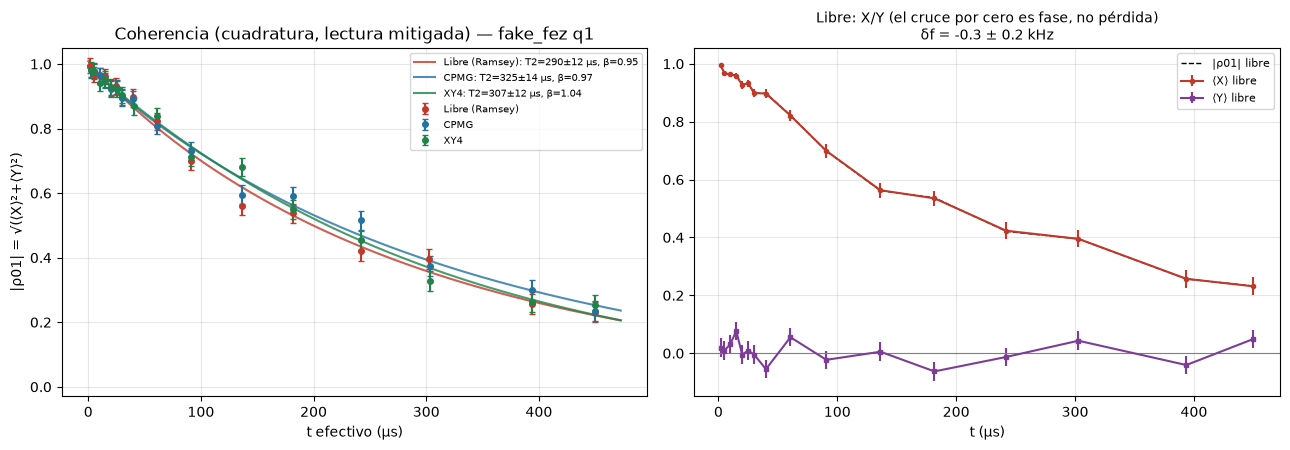

In [7]:
res = analyze(manifest, counts)
print(summarize(res, manifest))
(OUT_DIR / "results.json").write_text(json.dumps(to_jsonable(res), indent=1))
fig = plot_coherence(res, manifest, OUT_DIR / "coherencia.png")

## 8. Relays: paired test for each neighbor

      espectador   P1 idle  P1 activo         Δ        p    P1 |1>         Δ        p
              q2    0.163%     0.142%   -0.020%    0.659    0.195%   +0.033%    0.335
              q0    0.439%     0.529%   +0.090%    0.173    0.651%   +0.212%    0.056
   q82 (control)    0.000%     0.000%   +0.000%    0.500    0.000%   +0.000%    0.500

Error de lectura por qubit P(1|0): ['0.44%', '0.32%', '0.54%', '0.00%']
ZZ con vecinos en |1> (free): -0.14 kHz  | t=15: dphi=-0.083 rad, |c|1/|c|0=0.982 t=30: dphi=+0.020 rad, |c|1/|c|0=1.007 t=61: dphi=-0.061 rad, |c|1/|c|0=1.005
ZZ con vecinos en |1> (cpmg): -0.04 kHz  | t=15: dphi=-0.010 rad, |c|1/|c|0=1.002 t=30: dphi=-0.074 rad, |c|1/|c|0=1.003 t=61: dphi=+0.019 rad, |c|1/|c|0=1.010


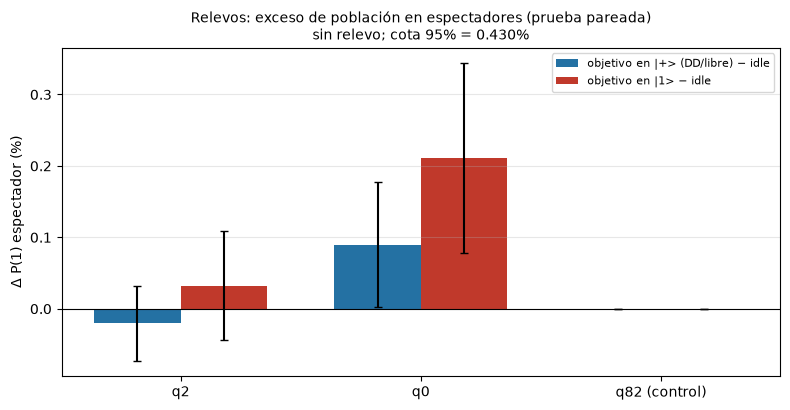

In [8]:
lay = manifest["layout"]
names = {f"vecino_bit{i+1}": f"q{q}" for i, q in enumerate(lay["neighbors"])}
names["control"] = f"q{lay['control']} (control)"
print(f"{'espectador':>16} {'P1 idle':>9} {'P1 activo':>10} {'Δ':>9} {'p':>8} {'P1 |1>':>9} {'Δ':>9} {'p':>8}")
for k, s in res["relay"].items():
    a, e = s["activo_vs_idle"], s["excitado_vs_idle"]
    print(f"{names[k]:>16} {a['p_ref']*100:8.3f}% {a['p_active']*100:9.3f}% {a['delta']*100:+8.3f}% {a['p_value']:8.3f}"
          f" {e['p_active']*100:8.3f}% {e['delta']*100:+8.3f}% {e['p_value']:8.3f}")
e0, e1 = res["readout"]["e0"], res["readout"]["e1"]
print("\nError de lectura por qubit P(1|0):", [f"{x*100:.2f}%" for x in e0])
if res.get("zz"):
    for p, z in res["zz"].items():
        print(f"ZZ con vecinos en |1> ({p}): {z['zz_kHz']:+.2f} kHz  |",
              " ".join(f"t={r['t']:.0f}: dphi={r['dphi']:+.3f} rad, |c|1/|c|0={r['mag1']/max(r['mag0'],1e-3):.3f}" for r in z["rows"]))
fig = plot_relay(res, manifest, OUT_DIR / "relevos.png")

## 9. Hypothesis verdicts

In [9]:
print("=" * 72)
ext = res["extension"]
for p in ("cpmg", "xy4"):
    if p in ext:
        e = ext[p]
        print(f"H1 [{p.upper()} extiende la coherencia]: T2_{p}/T2* = {e['ratio']:.2f} ± {e['err']:.2f} -> "
              + ("CONFIRMADA (> 2σ)" if e["significant"] else "NO confirmada"))
fits = res["fits"]
if fits.get("free"):
    b = fits["free"]["beta"]; eb = fits["free"]["beta_err"]
    print(f"H2 [ruido de baja frecuencia en libre, β>1]: β = {b:.2f} ± {eb:.2f} -> "
          + ("CONFIRMADA" if b - 1 > 2 * eb else "NO confirmada (decaimiento ~exponencial)"))
d = res.get("detuning")
if d:
    print(f"H3 [el cruce por cero del canal libre es detuning]: δf = {d['f_kHz']:+.2f} ± {d['f_err_kHz']:.2f} kHz -> "
          + ("CONFIRMADA" if abs(d["f_kHz"]) > 3 * d["f_err_kHz"] else "no hay detuning apreciable"))
rv = res["relay_verdict"]
print("H4 [no hay relevo a vecinos]: " + ("RECHAZADA, relevo en " + str(rv["flagged"]) if rv["relay_detected"]
      else f"CONFIRMADA, transferencia < {rv['worst_upper95']*100:.3f} % (95 %)"))
print("Verificacion estructural:", "sin SWAP ni 2q" if manifest["structural_check"]["ok"] else "PROBLEMAS")
print("=" * 72)

H1 [CPMG extiende la coherencia]: T2_cpmg/T2* = 1.12 ± 0.07 -> NO confirmada
H1 [XY4 extiende la coherencia]: T2_xy4/T2* = 1.06 ± 0.06 -> NO confirmada
H2 [ruido de baja frecuencia en libre, β>1]: β = 0.95 ± 0.07 -> NO confirmada (decaimiento ~exponencial)
H3 [el cruce por cero del canal libre es detuning]: δf = -0.31 ± 0.15 kHz -> no hay detuning apreciable
H4 [no hay relevo a vecinos]: CONFIRMADA, transferencia < 0.430 % (95 %)
Verificacion estructural: sin SWAP ni 2q


## 10. Reference: reanalysis of v1–v3 (`ibm_fez`, q142)
Results from `scripts/reanalyze_previous.py` in this repository, based on previously collected data:

| Quantity | Previously reported | Reanalysis |
|---|---|---|
| Free detuning | 53.9 kHz (v2) | **27.14 ± 0.06 kHz** (v2 aliasing from 26 µs step) |
| Free T2* | 5.2 µs (v1), 61.8 µs (v2) | **139 ± 7 µs** (β = 1.00) |
| CPMG T2 | 55.9 / 249 / 138 µs | **178 ± 5 µs** (combined, C = 0) |
| XY4 T2 | 48 / 144 / 189 µs | **193 ± 9 µs** |
| CPMG/free extension | 10.7x, 3.2x | **1.28 ± 0.07x** |
| Relay to neighbors (v3) | “no relay” (invalid criterion) | **< 0.145%** (absolute 95% upper bound) |
| Optimal N (60 µs) | 16 | flat curve (χ²_red = 0.49): N does not matter from 2 to 24 |

With v4, if `force_target=142`, use these values as the comparison baseline.

### Remaining limitations
- Standard readout does not distinguish |2⟩: leakage into non-computational states would appear as coherence loss. A three-level discriminator could be added when supported by the backend.
- Long-range crosstalk: direct neighbors and one distant control are covered. `n_neighbors` could be increased, or a distance-2 ring could be measured without adding circuits.
- Drift between jobs (χ²_red of 4–11 between v2 and v3) suggests repeating v4 two or three times to report a mean with realistic dispersion.
